# Основы глубинного обучения, майнор ИАД

## Домашнее задание 1: полносвязные сети

**ФИО:** Артемьев Никита Константинович

**Факт о себе:** Люблю сладкое и пиво!


## Общая информация

__Дата выдачи:__ 28.09.2026

__Мягкий дедлайн:__ 23:59MSK 18.10.2026

__Жесткий дедлайн:__ 23:59MSK 25.10.2026


## Оценивание и штрафы

Максимально допустимая оценка за работу — 10 баллов. Сдавать задание после указанного срока сдачи нельзя.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов. Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).  Если два студента сгенерировали в нейронке одинаковые либо похожие решения, это считается плагиатом и приводит к обнулению обеих работ.

Неэффективная реализация кода может негативно отразиться на оценке. Также оценка может быть снижена за плохо читаемый код и плохо оформленные графики. Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

Итогова оценка считается как

$$
min(part_1, part_2) \cdot 0.6 + max(part_1, part_2) \cdot 0.2 + part_3 \cdot 0.2
$$

где $part_1$, $part_2$ и $part_3$ - оценки за первую, вторую и третью части работы

> Также, за домашнее задание выставляется 0, если не сделано нулевое задание либо нет подробного описания ваших экспериментов в третьей части.

## Оформление

1. Обязательно фиксируйте зерно генератора случайных чисел в экспериментах. При перезапуске кода значения не должны меняться.
2. Вверху файла подпишите фамилию, имя и какой-то занимательный факт о себе.
3. Обратите внимание, что у графиков должны быть подписаны оси, заголовок графика и при необходимости обязательно наличие легенды. 

> За отсутствие названий графиков и подписей к осям могут снижаться баллы. Все картинки должны быть самодостаточны и визуально удобны для восприятия, так чтобы не нужно было смотреть ваш код или знать задание, чтобы понять что на них изображено.

Из каждого проведённого эксперимента делайте выводы и фиксируйте их. Эти выводы не должны быть поверхностными и очевидными. Не будьте мудрым королём.

<br>

<center>
<img src="https://raw.githubusercontent.com/hse-ds/iad-deep-learning/refs/heads/master/2025/homeworks/king.png" width="300"> 
</center>

**Пример плохого вывода:** Синенькая линия идет вверх, а красная вниз. Черненькая идет вниз, а потом вверх. 

<br>

<center>
<img src="https://raw.githubusercontent.com/hse-ds/iad-deep-learning/refs/heads/master/2025/homeworks/bad_lines.png" width="600"> 
</center>

## О задании

Вам предстоит обучить полносвязную нейронную сеть для предсказания года выпуска песни по ее аудио-признакам. Для этого мы будем использовать [Million Songs Dataset](https://samyzaf.com/ML/song_year/song_year.html).

In [81]:
import torch
from torch import nn
import torch.nn.functional as F

import pandas as pd
import numpy as np
import random

from tqdm.notebook import tqdm
from IPython.display import clear_output
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

Начнем с того, что скачаем и загрузим данные:

In [82]:
# !wget -O yearpredictionmsd.zip https://archive.ics.uci.edu/static/public/203/yearpredictionmsd.zip

In [83]:
df = pd.read_csv('yearpredictionmsd.zip', header=None)
df.head()

,0,1,2,3,4,5,6,7,8,9,...,81,82,83,84,85,86,87,88,89,90
0,2001,49.94357,21.47114,73.07750,8.74861,-17.40628,-13.09905,-25.01202,-12.23257,7.83089,...,13.01620,-54.40548,58.99367,15.37344,1.11144,-23.08793,68.40795,-1.82223,-27.46348,2.26327
1,2001,48.73215,18.42930,70.32679,12.94636,-10.32437,-24.83777,8.76630,-0.92019,18.76548,...,5.66812,-19.68073,33.04964,42.87836,-9.90378,-32.22788,70.49388,12.04941,58.43453,26.92061
2,2001,50.95714,31.85602,55.81851,13.41693,-6.57898,-18.54940,-3.27872,-2.35035,16.07017,...,3.03800,26.05866,-50.92779,10.93792,-0.07568,43.20130,-115.00698,-0.05859,39.67068,-0.66345
3,2001,48.24750,-1.89837,36.29772,2.58776,0.97170,-26.21683,5.05097,-10.34124,3.55005,...,34.57337,-171.70734,-16.96705,-46.67617,-12.51516,82.58061,-72.08993,9.90558,199.62971,18.85382
4,2001,50.97020,42.20998,67.09964,8.46791,-15.85279,-16.81409,-12.48207,-9.37636,12.63699,...,9.92661,-55.95724,64.92712,-17.72522,-1.49237,-7.50035,51.76631,7.88713,55.66926,28.74903


Посмотрим на статистики по данным.

In [84]:
df.describe()

,0,1,2,3,4,5,6,7,8,9,...,81,82,83,84,85,86,87,88,89,90
count,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,...,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000
mean,1998.397082,43.387126,1.289554,8.658347,1.164124,-6.553601,-9.521975,-2.391089,-1.793236,3.727876,...,15.755406,-73.461500,41.542422,37.934119,0.315751,17.669213,-26.315336,4.458641,20.035136,1.329105
std,10.931046,6.067558,51.580351,35.268585,16.322790,22.860785,12.857751,14.571873,7.963827,10.582861,...,32.099635,175.618889,122.228799,95.050631,16.161764,114.427905,173.977336,13.346557,185.558247,22.088576
min,1922.000000,1.749000,-337.092500,-301.005060,-154.183580,-181.953370,-81.794290,-188.214000,-72.503850,-126.479040,...,-437.722030,-4402.376440,-1810.689190,-3098.350310,-341.789120,-3168.924570,-4319.992320,-236.039260,-7458.378150,-381.424430
25%,1994.000000,39.954690,-26.059520,-11.462710,-8.487500,-20.666450,-18.440990,-10.780600,-6.468420,-2.293660,...,-1.812650,-139.555160,-20.986900,-4.669540,-6.781590,-31.580610,-101.530300,-2.566090,-59.509270,-8.820210
50%,2002.000000,44.258500,8.417850,10.476320,-0.652840,-6.007770,-11.188390,-2.046670,-1.736450,3.822310,...,9.171850,-53.090060,28.791060,33.623630,0.820840,15.598470,-21.204120,3.117640,7.759730,0.053050
75%,2006.000000,47.833890,36.124010,29.764820,8.787540,7.741870,-2.388960,6.508580,2.913450,9.961820,...,26.274480,13.478730,89.661770,77.785800,8.470990,67.794960,52.389330,9.967740,86.351610,9.679520
max,2011.000000,61.970140,384.065730,322.851430,335.771820,262.068870,166.236890,172.402680,126.741270,146.297950,...,840.973380,4469.454870,3210.701700,1734.079690,260.544900,3662.065650,2833.608950,463.419500,7393.398440,677.899630


Целевая переменная, год выпуска песни, записана в первом столбце. Посмотрим на ее распределение.

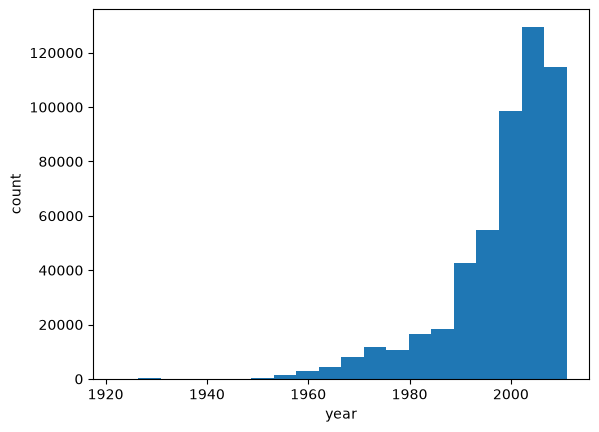

Range: 1922 - 2011
Unique values: 89


In [85]:
plt.hist(df.iloc[:, 0], bins=20)
plt.xlabel('year')
plt.ylabel('count')
plt.show()
print(f'Range: {df.iloc[:, 0].min()} - {df.iloc[:, 0].max()}')
print(f'Unique values: {np.unique(df.iloc[:, 0]).size}')

Разобьем данные на обучение и тест (не меняйте здесь ничего, чтобы сплит был одинаковым у всех).

In [86]:
X = df.iloc[:, 1:].values
y = df.iloc[:, 0].values

train_size = int(0.75 * X.shape[0])

X_train = X[:train_size, :]
y_train = y[:train_size]
X_test = X[train_size:, :]
y_test = y[train_size:]

X_train.shape, X_test.shape

((386508, 90), (128837, 90))

## Полезные советы:

- Если вы сразу реализуете обучение на GPU, то у вас будет больше времени на эксперименты, так как любые вычисления будут работать быстрее. Google Colab предоставляет несколько GPU-часов (обычно около 8-10) в сутки бесплатно.

- Если вы чего-то не знаете, не стесняйтесь гуглить. В интернете очень много полезной информации, туториалов и советов по глубинному обучению и `pytorch`. Но не забывайте, что за списанный код без ссылки на источник последует наказание.

- Чтобы отладить код, можете обучаться на небольшой части данных или даже на одном батче. Если лосс на обучающей выборке не падает, то что-то точно идет не так.

- Пользуйтесь утилитами, которые вам предоставляет `pytorch` (например, `Dataset` и `Dataloader`). Их специально разработали для упрощения разработки пайплайна обучения.

- Скорее всего, вы захотите отслеживать прогресс обучения. Для создания прогресс-баров есть удобная библиотека `tqdm`.

- Быть может, вы захотите, чтобы графики рисовались прямо во время обучения. Можете воспользоваться функцией [clear_output](http://ipython.org/ipython-doc/dev/api/generated/IPython.display.html#IPython.display.clear_output), чтобы удалять старый график и рисовать новый на его месте.

- При желании вы можете логгировать метрики обучения и свои эксперименты в WandB либо любой другой сервис. Не забудьте приложить к тетрадке ссылку на результаты экспериментов либо скришноты графиков с пояснениями, что проверяющий должен на них увидеть.

- Финальное значение тестовой метрики для удобства проверки выведите в тетрадке.

## Задание 0 (0 баллов, но при невыполнении максимальная оценка за всю работу &mdash; 0 баллов)

Мы будем использовать RMSE как метрику качества. Прежде чем обучать нейронные сети, нам нужно проверить несколько простых бейзлайнов, чтобы было с чем сравнить более сложные алгоритмы. Для этого бучите `Ridge` регрессию из `sklearn`. Кроме того, посчитайте качество при наилучшем константном прогнозе.

Для выполнения данного задания (и всех последующих) предобработайте данные.

1. Зафиксируйте random_seed везде где только возможно. Вам предоставлена функция для этого, однако вы можете дополнить ее своими дополнениями.
2. Обучите `StandertScaler` и предобработайте ваши данные. В следующих заданиях можете использовать другой `scaler` или вообще отказаться от него.


In [87]:
def set_global_seed(seed: int) -> None:
    """Set global seed for reproducibility.
    :param int seed: Seed to be set
    """
    torch.backends.cudnn.deterministic = True
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)

    # также можно зафиксировать seed для Dataloader
    g = torch.Generator()
    g.manual_seed(seed)
    return g

# Сид для каждого worker в Dataloader
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = set_global_seed(42)

In [88]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline

ridge = make_pipeline(StandardScaler(), Ridge())
ridge.fit(X[:train_size], y[:train_size])
ridge_pred = ridge.predict(X_test)

rmse_for_model = np.sqrt(np.mean((y_test - ridge_pred) ** 2))
print(f"Ridge test RMSE: {rmse_for_model:.4f}")

Ridge test RMSE: 9.4736


Лучшая константа для RMSE это среднее. Используйте среднее, расчитанное на трэйне в качестве прогноза для теста и посчитайте для такой наивной модели RMSE.

In [89]:
best_rmse_metric = np.sqrt(np.mean((y_test - y[:train_size].mean()) ** 2))
print(f"Константа (среднее train) test RMSE: {best_rmse_metric:.4f}")

Константа (среднее train) test RMSE: 10.8455


Теперь приступим к экспериментам с нейросетями. Для начала отделим от данных валидацию. Тестовую выборку мы будем использовать только для того, чтобы измерить итоговую метрику качества модели.

In [90]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X[:train_size], y[:train_size], test_size=0.25, random_state=0xE2E4)
X_train.shape, X_val.shape

((289881, 90), (96627, 90))

ИТОГ

| модель | test RMSE, годы |
|---|---|
| константа (среднее train) | 10.85 |
| Ridge (α = 1) на стандартизованных признаках | 9.47 |

Ridge лучше константы примерно на 1,4 года. Ridge обучен на всём train (75% данных) до отделения валидации.

## Часть I. Обучаем линейную регрессию (максимум 10 баллов)

**Задание 1 (10 баллов):** Обучите в `pytorch` линейную регрессию. 

- Создайте модель линейной регрессии, которая будет состоять только из одного `Linear()` слоя.
   
- Напишите цикл обучения вашей линейной регрессии. В нем реализуйте подсчет функции потерь, сделайте шаг градиентного спуска. Запрещено использовать готовые оптимизаторы и loss-функции из библиотеки `pytorch`. Для подсчета градиента воспользуйтесь методом backward.
   
- Запустите обучение на 10 эпохах, после каждой проверяйте значение целевой метрики на тестовой выборке.
   
- Выведите на экран графики метрики и значения функции потерь на тестовой и обучающей выборке.

В данном задании нет цели побить какой-то порог по метрике. Ваша задача &mdash; убедиться в том, что ваш рукописный цикл обучения работает. Для ускорения вычислений и обучения модели можете брать только срез данных, а не весь датасет.

In [91]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32, device=device)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32, device=device).reshape(-1, 1)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32, device=device)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32, device=device).reshape(-1, 1)

In [92]:
def mse_loss(pred, target):
    return ((pred - target) ** 2).mean()

def sgd_step(model, lr):
    with torch.no_grad():
        for parametr in model.parameters():
            parametr -= lr * parametr.grad
            parametr.grad = None

def train_epoch(model, X, y, lr, batch_size, generator):
    n = X.shape[0]
    perm = torch.randperm(n, generator=generator)
    for start in range(0, n, batch_size):
        idx = perm[start:start + batch_size]
        loss = mse_loss(model(X[idx]), y[idx])
        loss.backward()
        sgd_step(model, lr)

@torch.no_grad()
def evaluate(model, X, y):
    loss = mse_loss(model(X), y)
    return loss.item(), torch.sqrt(loss).item()

In [93]:
g = set_global_seed(42)
model = nn.Linear(X_train_tensor.shape[1], 1).to(device)
with torch.no_grad():
    model.bias.fill_(y_train_tensor.mean())

lr = 1e-3
batch_size = 256
epochs = 10

train_losses, test_losses = [], []
train_rmses, test_rmses = [], []

for epoch in range(1, epochs + 1):
    train_epoch(model, X_train_tensor, y_train_tensor, lr, batch_size, g)

    train_loss, train_rmse = evaluate(model, X_train_tensor, y_train_tensor)
    test_loss, test_rmse = evaluate(model, X_test_tensor, y_test_tensor)
    
    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_rmses.append(train_rmse)
    test_rmses.append(test_rmse)

    print(f"epoch {epoch:02d}  train MSE {train_loss:.2f}  test MSE {test_loss:.2f}  "
          f"train RMSE {train_rmse:.3f}  test RMSE {test_rmse:.3f}")

epoch 01  train MSE 95.31  test MSE 93.76  train RMSE 9.763  test RMSE 9.683
epoch 02  train MSE 92.85  test MSE 91.25  train RMSE 9.636  test RMSE 9.552
epoch 03  train MSE 92.11  test MSE 90.43  train RMSE 9.597  test RMSE 9.510
epoch 04  train MSE 91.80  test MSE 90.15  train RMSE 9.581  test RMSE 9.495
epoch 05  train MSE 91.72  test MSE 90.07  train RMSE 9.577  test RMSE 9.490
epoch 06  train MSE 91.61  test MSE 89.91  train RMSE 9.571  test RMSE 9.482
epoch 07  train MSE 91.59  test MSE 89.88  train RMSE 9.570  test RMSE 9.481
epoch 08  train MSE 91.57  test MSE 89.86  train RMSE 9.569  test RMSE 9.480
epoch 09  train MSE 91.56  test MSE 89.83  train RMSE 9.569  test RMSE 9.478
epoch 10  train MSE 91.56  test MSE 89.84  train RMSE 9.569  test RMSE 9.479


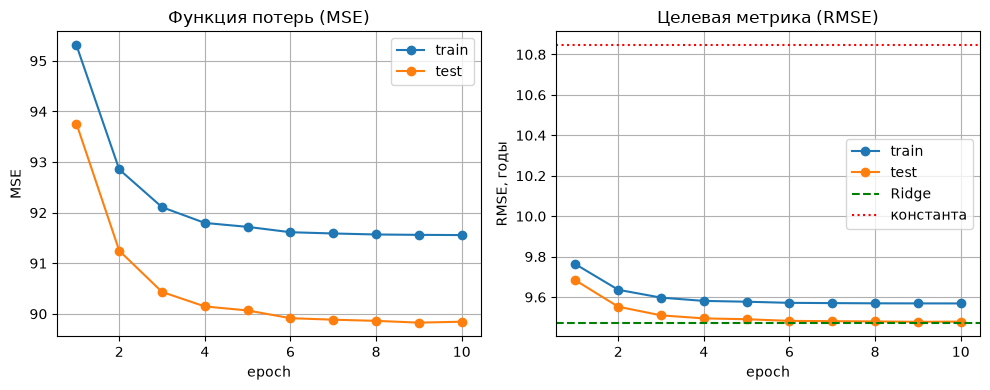

Финальный test RMSE: 9.4786
Ridge test RMSE:     9.4736
Константа (среднее): 10.8455


In [94]:
epochs_axis = range(1, len(train_losses) + 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(epochs_axis, train_losses, marker="o", label="train")
axes[0].plot(epochs_axis, test_losses, marker="o", label="test")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("MSE")
axes[0].set_title("Функция потерь (MSE)")

axes[1].plot(epochs_axis, train_rmses, marker="o", label="train")
axes[1].plot(epochs_axis, test_rmses, marker="o", label="test")
axes[1].axhline(rmse_for_model, color="green", linestyle="--", label="Ridge")
axes[1].axhline(best_rmse_metric, color="red", ls=":", label="константа")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("RMSE, годы")
axes[1].set_title("Целевая метрика (RMSE)")

for ax in axes:
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

print(f"Финальный test RMSE: {test_rmses[-1]:.4f}")
print(f"Ridge test RMSE:     {rmse_for_model:.4f}")
print(f"Константа (среднее): {best_rmse_metric:.4f}")

**Вывод по заданию 1.**

Написанный цикл обучения работает: MSE и RMSE на train и test монотонно падают и к 6–7 эпохе выходят на плато. После 10 эпох test RMSE = 9.48, у Ridge 9.47, у константы 10.85. Линейная модель, обученная GD, сошлась почти к тому же, что и Ridge.

Кривые train и test идут почти вплотную: переобучения нет.

Выбор шага: в пробном запуске с `lr = 1e-2` метрика скакала между эпохами, `lr = 1e-3` даёт плавное снижение. Bias инициализирован средним таргета, поэтому кривые стартуют сразу от уровня константного прогноза.

## Часть II. Заводим нейронную сеть (максимум 10 баллов)

Ниже нам предстоит реализовать довольно много различных нейросетей и поставить целую серию экспериментов. Чтобы это всё происходило без боли и страданий, нам нужно держать код в удобном виде.

При решении заданий вы можете придерживаться любой адекватной струкуры кода, но мы советуем воспользоваться сигнатурами функций, которые приведены ниже. При необходимости вы можете добавить в них любые нужные вам аргументы и любой нужный функционал. Более того, хорошей практикой является не делать эти функции слишком громоздкими и выносить разные хитрые штуки в отдельные функции.

In [95]:
def training_epoch(model, optimizer, criterion, train_loader):
    """Одна эпоха обучения
    params:
        model - torch.nn.Module to be fitted
        optimizer - model optimizer
        criterion - loss function from torch.nn
        train_loader - torch.utils.data.Dataloader with train set
    """
    model.train()
    device = next(model.parameters()).device

    total_loss = 0.0
    n_samples = 0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        predicts = model(X_batch)
        loss = criterion(predicts, y_batch)
        loss.backward()
        optimizer.step()

        batch_size = X_batch.size(0)
        total_loss += loss.item() * batch_size
        n_samples += batch_size

    return total_loss / n_samples


@torch.no_grad()
def validation_epoch(model, criterion, val_loader):
    """Одна эпоха валидации модели
    params:
        model - torch.nn.Module to be fitted
        criterion - loss function from torch.nn
        val_loader - torch.utils.data.Dataloader with test set
                      (if you wish to validate during training)
    """
    model.eval()
    device = next(model.parameters()).device

    total_loss = 0.0
    n_samples = 0

    for X_batch, y_batch in val_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        predicts = model(X_batch)
        loss = criterion(predicts, y_batch)

        batch_size = X_batch.size(0)
        total_loss += loss.item() * batch_size
        n_samples += batch_size

    return total_loss / n_samples

@torch.no_grad()
def predict(model, data_loader):
    """ Предсказания модели
    params:
        model - torch.nn.Module to be evaluated on test set
        criterion - loss function from torch.nn
        data_loader - torch.utils.data.Dataloader with test set
    ----------
    returns:
        predicts - torch.tensor with shape (len(test_loader.dataset), ),
                   which contains predictions for test objects
    """
    model.eval()
    device = next(model.parameters()).device
    chunks = []

    for X_batch, _ in data_loader:
        out = model(X_batch.to(device))

        if out.ndim > 1 and out.shape[1] > 1:
            batch_predict = out.argmax(dim=1)
        else:
            batch_predict = out.reshape(-1)
        
        chunks.append(batch_predict.cpu())
    
    return torch.cat(chunks, dim=0)


def train(model, optimizer, criterion, train_loader, val_loader, epochs):
    """ Обучение модели
    params:
        model - torch.nn.Module to be fitted
        optimizer - model optimizer
        criterion - loss function from torch.nn
        train_loader - torch.utils.data.Dataloader with train set
        val_loader - torch.utils.data.Dataloader with test set
                      (if you wish to validate during training)
        epochs - number of training epochs
    """
    train_losses = []
    val_losses = []

    for epoch in range(1, epochs + 1):
        train_loss = training_epoch(model, optimizer, criterion, train_loader)
        val_loss = validation_epoch(model, criterion, val_loader)

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        print(f"epoch {epoch:02d}  train loss {train_loss:.4f}  val loss {val_loss:.4f}")
    
    return train_losses, val_losses


**Задание 2 (2 балла)**

Попробуем обучить нашу первую нейронную сеть. Здесь целевая переменная дискретная &mdash; это год выпуска песни. Поэтому будем учить сеть на классификацию.

- В качестве архитектуры сети возьмите два линейных слоя с активацией ReLU между ними c числом скрытых нейронов, равным 128.
- Используйте SGD с `lr=1e-3`.
- Возьмите размер мини-батча около 32-64, примерно 3-4 эпох обучения должно быть достаточно.
- Также преобразуйте целевую переменную так, чтобы ее значения принимали значения от $0$ до $C-1$, где $C$ &mdash; число классов (лучше передайте преобразованное значение в DataLoader, исходное нам еще пригодится)
- В качестве метрики качества мы используем RMSE. При его подсчёте вам нужно заменить предсказанный нейросеткой класс на конкретный год выпуска песни и использовать его как прогноз. 

Преобразование над target: год переводим в класс

In [96]:
from torch.utils.data import TensorDataset, DataLoader

year_min, year_max = y_train.min(), y_train.max()
n_classes = year_max - year_min + 1

def year_to_class(years):
    return years - year_min

def class_to_year(classes):
    return classes + year_min

Преобразование train, validate, test в DataLoader

In [97]:
def data_loader_class(X, years, shuffle, batch_size=64):
    dataset = TensorDataset(torch.tensor(X, dtype=torch.float32),
                            torch.tensor(year_to_class(years), dtype=torch.long))
    # свой генератор, так как порядок батчей не зависит от того, какие ячейки запускались раньше
    generator = torch.Generator().manual_seed(42) if shuffle else None
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, generator=generator)

train_eval_loader_class = data_loader_class(X_train_scaled, y_train, shuffle=True)
val_loader_class = data_loader_class(X_val_scaled, y_val, shuffle=False)
test_loader_class = data_loader_class(X_test_scaled, y_test, shuffle=False)

In [98]:
@torch.no_grad()
def rmse_years(model, loader):
    model.eval()
    se, n = 0.0, 0
    for X_batch, y_batch in loader:
        pred_years = class_to_year(model(X_batch.to(device)).argmax(1).cpu().numpy())
        true_years = class_to_year(y_batch.numpy())
        se += np.sum((true_years - pred_years) ** 2)
        n += len(true_years)
    return np.sqrt(se / n)

In [99]:
set_global_seed(42)
train_loader_class = data_loader_class(X_train_scaled, y_train, shuffle=True)
model = nn.Sequential(
    nn.Linear(X_train_scaled.shape[1], 128),
    nn.ReLU(),
    nn.Linear(128, n_classes),
).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

epochs = 4
for epoch in range(1, epochs + 1):
    train_ce = training_epoch(model, optimizer, criterion, train_loader_class)
    val_ce = validation_epoch(model, criterion, val_loader_class)
    train_rmse = rmse_years(model, train_eval_loader_class)
    val_rmse = rmse_years(model, val_loader_class)
    print(f"epoch {epoch:02d}: CE train {train_ce:.4f} | CE val {val_ce:.4f} | "
          f"RMSE train {train_rmse:.4f} | RMSE val {val_rmse:.4f}")

test_rmse_class = rmse_years(model, test_loader_class)
print(f"Test RMSE (классификация): {test_rmse_class:.4f}")

epoch 01: CE train 4.0747 | CE val 3.7854 | RMSE train 13.6178 | RMSE val 13.6422
epoch 02: CE train 3.6495 | CE val 3.5588 | RMSE train 13.5378 | RMSE val 13.5600
epoch 03: CE train 3.5150 | CE val 3.4792 | RMSE train 13.4625 | RMSE val 13.4930
epoch 04: CE train 3.4557 | CE val 3.4353 | RMSE train 13.3441 | RMSE val 13.3830
Test RMSE (классификация): 13.2514


In [100]:
pred_years = class_to_year(predict(model, test_loader_class).numpy())
years, counts = np.unique(pred_years, return_counts=True)
top = counts.argsort()[::-1][:5]
print(f"Сеть предсказывает {len(years)} разных годов из {n_classes}")
print("Самые частые предсказания (год: доля):",
      {int(yr): round(c / len(pred_years), 3) for yr, c in zip(years[top], counts[top])})

train_years, train_counts = np.unique(y_train, return_counts=True)
mode_year = train_years[train_counts.argmax()]
rmse_mode = np.sqrt(np.mean((y_test - mode_year) ** 2))
print(f"Константа = самый частый год train ({mode_year}): test RMSE {rmse_mode:.4f}")
print(f"Константа = среднее train:                 test RMSE {best_rmse_metric:.4f}")
print(f"Ridge:                                     test RMSE {rmse_for_model:.4f}")

Сеть предсказывает 16 разных годов из 90
Самые частые предсказания (год: доля): {2007: np.float64(0.355), 2006: np.float64(0.234), 2005: np.float64(0.154), 2008: np.float64(0.132), 2009: np.float64(0.038)}
Константа = самый частый год train (2007): test RMSE 13.8026
Константа = среднее train:                 test RMSE 10.8455
Ridge:                                     test RMSE 9.4736


**Задание 3 (1 балл).** Прокомментируйте ваши наблюдения. Удалось ли побить бейзлайн? Как вы думаете, хорошая ли идея учить классификатор для этой задачи? Почему?

CE на train падает с 4.07 до 3.46, на val с 3.79 до 3.44. Но RMSE на val за те же эпохи почти не меняется (с 13.64 до 13.38).

Бейзлайн не побит. После 4 эпох test RMSE классификатора 13.25, а у Ridge 9.47. Классификатор хуже даже константы.

Почему все плохо: 
1. CrossEntropy не знает, что классы упорядочены. Промах на 1 год и на 40 лет для неё одинаково «не тот класс». RMSE же штрафует за промах квадратично по расстоянию. 
2. Argmax тянет предсказания к самому частому году. Распределение лет скошено влево: константа «всегда 2007» даёт test RMSE 13.80, классификатор немного лучше. RMSE минимизирует среднее 1998, а argmax выбирает моду, а для скошенного распределения они далеки друг от друга.
3. Функция потерь не согласована с метрикой. Если все же решать как классификацию, то прогнозом стоит брать не argmax, а матожидание года по softmax - это ближе к тому, что минимизирует RMSE.

**Задание 4 (2 балла).** Теперь попробуем решать задачу как регрессию. Обучите нейронную сеть на MSE.

- Используйте такие же гиперпараметры обучения.
- Когда передаете целевую переменную в DataLoader, сделайте reshape в (-1, 1).
- Если что-то пойдет не так, можете попробовать меньшие значения `lr`.

Признаки намеренно не масштабируем. Масштабировать будем в следующих заданиях.

In [101]:
def regression_data_loader(X, years, shuffle, batch_size=64):
    dataset = TensorDataset(torch.tensor(X, dtype=torch.float32),
                            torch.tensor(years, dtype=torch.float32).reshape(-1, 1))
    generator = torch.Generator().manual_seed(42) if shuffle else None
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, generator=generator)

train_eval_loader_reg = regression_data_loader(X_train, y_train, shuffle=False)
val_loader_reg = regression_data_loader(X_val, y_val, shuffle=False)

In [102]:
def run_regression(lr, epochs=3):
    set_global_seed(42)
    
    train_loader = regression_data_loader(X_train, y_train, shuffle=True)
    model = nn.Sequential(
        nn.Linear(X_train.shape[1], 128),
        nn.ReLU(),
        nn.Linear(128, 1),
    ).to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    logs = {"train_rmse": [], "val_rmse": []}
    for epoch in range(1, epochs + 1):
        train_mse = training_epoch(model, optimizer, criterion, train_loader)

        if not np.isfinite(train_mse):
            print(f"lr={lr:.0e}  epoch {epoch:02d}: loss = nan, обучение разошлось")
            break

        logs["train_rmse"].append(np.sqrt(validation_epoch(model, criterion, train_eval_loader_reg)))
        logs["val_rmse"].append(np.sqrt(validation_epoch(model, criterion, val_loader_reg)))
        print(f"lr={lr:.0e}  epoch {epoch:02d}: RMSE train {logs['train_rmse'][-1]:.2f} | RMSE val {logs['val_rmse'][-1]:.2f}")

    return logs

reg_logs = {lr: run_regression(lr) for lr in [1e-3, 1e-4, 1e-5, 1e-6, 1e-7]}

lr=1e-03  epoch 01: loss = nan, обучение разошлось
lr=1e-04  epoch 01: loss = nan, обучение разошлось
lr=1e-05  epoch 01: RMSE train 1141306179410.97 | RMSE val 1141306179410.97
lr=1e-05  epoch 02: RMSE train 1042449419328.71 | RMSE val 1042449419328.71
lr=1e-05  epoch 03: RMSE train 952153881940.95 | RMSE val 952153881944.21
lr=1e-06  epoch 01: RMSE train 1981.78 | RMSE val 1981.79
lr=1e-06  epoch 02: RMSE train 1963.91 | RMSE val 1963.92
lr=1e-06  epoch 03: RMSE train 1946.29 | RMSE val 1946.30
lr=1e-07  epoch 01: RMSE train 790.96 | RMSE val 792.55
lr=1e-07  epoch 02: RMSE train 1526.78 | RMSE val 1526.16
lr=1e-07  epoch 03: RMSE train 1055.48 | RMSE val 1056.56


In [103]:
print(f"y_train: min {y_train.min():.2f}, max {y_train.max():.2f}, mean {y_train.mean():.2f}")
print(f"X_train: min {X_train.min():.2f}, max {X_train.max():.2f}")
print(f"X_train per feature max abs: {np.abs(X_train).max(axis=0).max():.2f}")

y_train: min 1922.00, max 2011.00, mean 1998.37
X_train: min -13795.87, max 65735.78
X_train per feature max abs: 65735.78


**Задание 5 (1 балл).** Получилось ли у вас стабилизировать обучение? Помогли ли меньшие значения `lr`? Стало ли лучше от замены классификации на регрессию? Как вы думаете, почему так происходит? В качестве подсказки можете посмотреть на распределение целевой переменной и магнитуду значений признаков.

**Ответ:** 

Обучение стабилизировать не получилось. Меньший `lr` убирает `nan`, полезной модели за 4 эпохи не получается. Замена классификации на регрессию качество не улучшила: лучший конечный RMSE здесь около 791. 

При `lr = 1e-3` и `1e-4` loss становится `nan` уже в первой эпохе. При `1e-5` переполнения нет, но RMSE порядка 10^12. При `1e-6` RMSE падает с 1982 до 1946 и всё ещё составляет около 2000 лет ошибки. При `1e-7` ошибка скачет: 791, затем 1527, затем 1056.

Причина в масштабе: Годы лежат в диапазоне 1922–2011, среднее train = 1998.4, поэтому начальная ошибка около 2000, а градиент MSE пропорционален ошибке. Признаки при этом от −13796 до 65736. Один шаг SGD одновременно слишком велик для крупных признаков и слишком мал, чтобы за несколько эпох прийти к 2000 году.

**Задание 6 (1 балл).** Начнем с того, что попробуем отнормировать целевую переменную. Для этого воспользуемся min-max нормализацией, чтобы целевая переменная принимала значения от 0 до 1. Реализуйте функции `normalize` и `denormalize`, которые, соответственно, нормируют целевую переменную и применяют обратное преобразование. Минимум и максимум оцените по обучающей выборке (то есть эти константы должны быть фиксированными и не зависеть от передаваемой выборки).

In [104]:
y_min = float(y_train.min())
y_max = float(y_train.max())

def normalize(sample):
    """
    Min-max normalization to convert sample to [0, 1] range
    """
    return (sample - y_min) / (y_max - y_min)
    

def denormalize(sample):
    """
    Denormalize sample from [0, 1] to initial range
    """
    return sample * (y_max - y_min) + y_min    

**Задание 7 (1 балл)** Теперь повторите эксперимент из **задания 4**, обучаясь на нормированной целевой переменной. Сделаем также еще одно изменение: добавим сигмоидную активацию после последнего линейного слоя сети. Таким образом мы гарантируем, что нейронная сеть предсказывает числа из промежутка $[0, 1]$. Использование активации - довольно распространенный прием, когда мы хотим получить числа из определенного диапазона значений. 

In [105]:
y_train_norm = normalize(y_train)
y_val_norm = normalize(y_val)
y_test_norm = normalize(y_test)

train_eval_loader_norm_reg = regression_data_loader(X_train, y_train_norm, shuffle=False)
val_loader_norm_reg = regression_data_loader(X_val, y_val_norm, shuffle=False)
test_loader_norm_reg = regression_data_loader(X_test, y_test_norm, shuffle=False)

In [106]:
def rmse_in_years(model, criterion, loader):
    return np.sqrt(validation_epoch(model, criterion, loader)) * (y_max - y_min)

In [107]:
set_global_seed(42)

train_loader_norm_reg = regression_data_loader(X_train, y_train_norm, shuffle=True)
model = nn.Sequential(
    nn.Linear(X_train.shape[1], 128),
    nn.ReLU(),
    nn.Linear(128, 1),
    nn.Sigmoid(),
).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

for epoch in range(1, 5):
    training_epoch(model, optimizer, criterion, train_loader_norm_reg)
    print(f"epoch {epoch:02d}: RMSE train {rmse_in_years(model, criterion, train_eval_loader_norm_reg):.4f} | "
          f"RMSE val {rmse_in_years(model, criterion, val_loader_norm_reg):.4f}")

test_rmse_sig = rmse_in_years(model, criterion, test_loader_norm_reg)
print(f"Test RMSE: {test_rmse_sig:.4f}  (константа-среднее {best_rmse_metric:.4f}, Ridge {rmse_for_model:.4f})")

epoch 01: RMSE train 16.7264 | RMSE val 16.7460
epoch 02: RMSE train 16.7258 | RMSE val 16.7450
epoch 03: RMSE train 16.7172 | RMSE val 16.7359
epoch 04: RMSE train 16.7153 | RMSE val 16.7346
Test RMSE: 16.5791  (константа-среднее 10.8455, Ridge 9.4736)


Вывод:

Нормировка таргета убрала nan, но сеть всё равно не учится. С третьей эпохи RMSE застывает на 16.72 (train) и 16.74 (val), и MSE больше не меняется. Это почти точно RMSE константы «всегда 2011» (16.58 на тесте), то есть сигмоида примерно 1 на всех объектах.

**Задание 8 (2 балла).** На этот раз попробуем отнормировать не только целевую переменную, но и сами данные, которые подаются сети на вход. Для них будем использовать нормализацию через среднее и стандартное отклонение. Преобразуйте данные и повторите прошлый эксперимент. Скорее всего, имеет смысл увеличить число эпох обучения.

In [108]:
x_scaler = StandardScaler()
X_train_std = x_scaler.fit_transform(X_train)
X_val_std = x_scaler.transform(X_val)
X_test_std = x_scaler.transform(X_test)

train_loader_std = regression_data_loader(X_train_std, y_train_norm, shuffle=True)
train_eval_loader_std = regression_data_loader(X_train_std, y_train_norm, shuffle=False)
val_loader_std = regression_data_loader(X_val_std, y_val_norm, shuffle=False)
test_loader_std = regression_data_loader(X_test_std, y_test_norm, shuffle=False)

In [109]:
set_global_seed(42)

train_loader = regression_data_loader(X_train_std, y_train_norm, shuffle=True)
model = nn.Sequential(
    nn.Linear(X_train_std.shape[1], 128),
    nn.ReLU(),
    nn.Linear(128, 1),
    nn.Sigmoid(),
).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

epochs = 10
logs_std = {"train_rmse": [], "val_rmse": []}
for epoch in range(1, epochs + 1):
    training_epoch(model, optimizer, criterion, train_loader)
    logs_std["train_rmse"].append(rmse_in_years(model, criterion, train_eval_loader_std))
    logs_std["val_rmse"].append(rmse_in_years(model, criterion, val_loader_std))
    print(f"epoch {epoch}: RMSE train {logs_std['train_rmse'][-1]:.4f} | RMSE val {logs_std['val_rmse'][-1]:.4f}")

test_rmse_std = rmse_in_years(model, criterion, test_loader_std)
print(f"Test RMSE: {test_rmse_std:.4f}")

epoch 1: RMSE train 11.9892 | RMSE val 12.0594
epoch 2: RMSE train 11.0069 | RMSE val 11.0734
epoch 3: RMSE train 10.7906 | RMSE val 10.8542
epoch 4: RMSE train 10.6831 | RMSE val 10.7447
epoch 5: RMSE train 10.6059 | RMSE val 10.6660
epoch 6: RMSE train 10.5428 | RMSE val 10.6015
epoch 7: RMSE train 10.4888 | RMSE val 10.5464
epoch 8: RMSE train 10.4413 | RMSE val 10.4979
epoch 9: RMSE train 10.3990 | RMSE val 10.4546
epoch 10: RMSE train 10.3607 | RMSE val 10.4154
Test RMSE: 10.2453


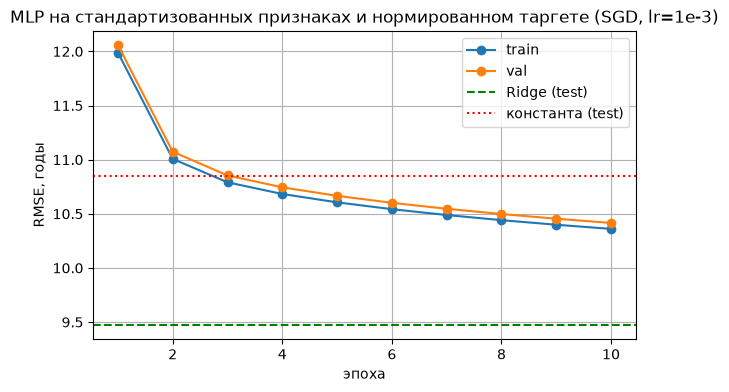

In [110]:
ep = range(1, epochs + 1)
plt.figure(figsize=(7, 4))
plt.plot(ep, logs_std["train_rmse"], marker="o", label="train")
plt.plot(ep, logs_std["val_rmse"], marker="o", label="val")
plt.axhline(rmse_for_model, color="green", ls="--", label="Ridge (test)")
plt.axhline(best_rmse_metric, color="red", ls=":", label="константа (test)")
plt.title("MLP на стандартизованных признаках и нормированном таргете (SGD, lr=1e-3)")
plt.xlabel("эпоха")
plt.ylabel("RMSE, годы")
plt.legend()
plt.grid(True)
plt.show()

Вывод:

Сеть заработала только после того, как и таргет, и признаки приведены к масштабу. Нормировка одного таргета не помогает. Уже после 1-й эпохи val RMSE 12.06, после десятой 10.42, это лучше константы 10.85. Train и val идут вплотную - разрыв 0.05, переобучения нет.

До Ridge 9.47 ещё около года, и кривая продолжает падать - обычный SGD с lr = 1e-3 сходится медленно. Сравнимое с Ridge качество здесь не достигается за 10 эпох.

Если вы все сделали правильно, то у вас должно было получиться качество, сравнимое с `Ridge` регрессией.

**Мораль:** как видите, нам пришлось сделать очень много хитрых телодвижений, чтобы нейронная сеть работала хотя бы так же, как и простая линейная модель. Здесь, конечно, показан совсем экстремальный случай, когда без нормализации данных нейронная сеть просто не учится. Как правило, в реальности завести нейронную сеть из коробки не очень сложно, но вот заставить ее работать на полную &mdash; куда более трудоемкая задача. Написание пайплайнов обучения нейросетевых моделей требует большой аккуратности, а дебаг часто превращается в угадайку. К счастью, очень часто на помощь приходит интуиция, и мы надеемся, что вы сможете выработать ее в течение нашего курса. Начнем с двух советов, которые стоит принять на вооружение:

- Обязательно начинаем любые эксперименты с бейзлайнов: без них мы бы не поняли, что нейронная сеть не учится в принципе.
- При постановке эксперментов старайтесь делать минимальное количество изменений за раз (в идеале одно!): только так можно понять, какие конкретно изменения влияют на результат.

## Часть III. Улучшаем нейронную сеть (максимум 10 баллов)

Продолжим экспериментировать с нейронной сетью, чтобы добиться еще лучшего качества.

Обобщим функцию, которая обучает модель и считает RMSE на train, val и test, чтобы передавать снаружи оптимизатор, Loss-функцию и модель.

In [111]:
def train_and_evaluate(make_model, make_optimizer, criterion, name, epochs=5):
    set_global_seed(42)
    
    model = make_model().to(device)
    optimizer = make_optimizer(model.parameters())
    mse = nn.MSELoss()

    train_loader = DataLoader(train_loader_std.dataset, batch_size=64, shuffle=True,
                              generator=torch.Generator().manual_seed(42))
    logs = {"train_rmse": [], "val_rmse": []}

    print(f"\n{name}")
    for epoch in range(1, epochs + 1):
        training_epoch(model, optimizer, criterion, train_loader)
        logs["train_rmse"].append(rmse_in_years(model, mse, train_eval_loader_std))
        logs["val_rmse"].append(rmse_in_years(model, mse, val_loader_std))
        print(f"epoch {epoch:02d}: RMSE train {logs['train_rmse'][-1]:.4f} | RMSE val {logs['val_rmse'][-1]:.4f}")

    logs["test_rmse"] = rmse_in_years(model, mse, test_loader_std)
    return model, logs

**Задание 9 (1 балл).** Давайте попробуем другие оптимизаторы. Обучите нейросеть с помощью SGD+momentum и Adam. Опишите свои наблюдения и в дальнейших запусках используйте лучший оптимизатор. Для Adam обычно берут learning rate поменьше, в районе $10^{-3}$.

In [112]:
def make_model():
    return nn.Sequential(
        nn.Linear(X_train_std.shape[1], 128),
        nn.ReLU(),
        nn.Linear(128, 1),
        nn.Sigmoid()
    )

optimizers = {
    "SGD": lambda p: torch.optim.SGD(p, lr=1e-3),
    "SGD+momentum": lambda p: torch.optim.SGD(p, lr=1e-3, momentum=0.9),
    "Adam": lambda p: torch.optim.Adam(p, lr=1e-3),
}

results = {}
for name, make_optimizer in optimizers.items():
    results[name] = train_and_evaluate(make_model, make_optimizer, nn.MSELoss(), name, 10)


SGD
epoch 01: RMSE train 11.9892 | RMSE val 12.0594
epoch 02: RMSE train 11.0069 | RMSE val 11.0734
epoch 03: RMSE train 10.7906 | RMSE val 10.8542
epoch 04: RMSE train 10.6831 | RMSE val 10.7447
epoch 05: RMSE train 10.6059 | RMSE val 10.6660
epoch 06: RMSE train 10.5428 | RMSE val 10.6015
epoch 07: RMSE train 10.4888 | RMSE val 10.5464
epoch 08: RMSE train 10.4413 | RMSE val 10.4979
epoch 09: RMSE train 10.3990 | RMSE val 10.4546
epoch 10: RMSE train 10.3607 | RMSE val 10.4154

SGD+momentum
epoch 01: RMSE train 10.3633 | RMSE val 10.4181
epoch 02: RMSE train 10.0961 | RMSE val 10.1463
epoch 03: RMSE train 9.9267 | RMSE val 9.9758
epoch 04: RMSE train 9.8017 | RMSE val 9.8511
epoch 05: RMSE train 9.7032 | RMSE val 9.7540
epoch 06: RMSE train 9.6232 | RMSE val 9.6757
epoch 07: RMSE train 9.5567 | RMSE val 9.6115
epoch 08: RMSE train 9.5008 | RMSE val 9.5574
epoch 09: RMSE train 9.4530 | RMSE val 9.5119
epoch 10: RMSE train 9.4117 | RMSE val 9.4727

Adam
epoch 01: RMSE train 8.8920 | R

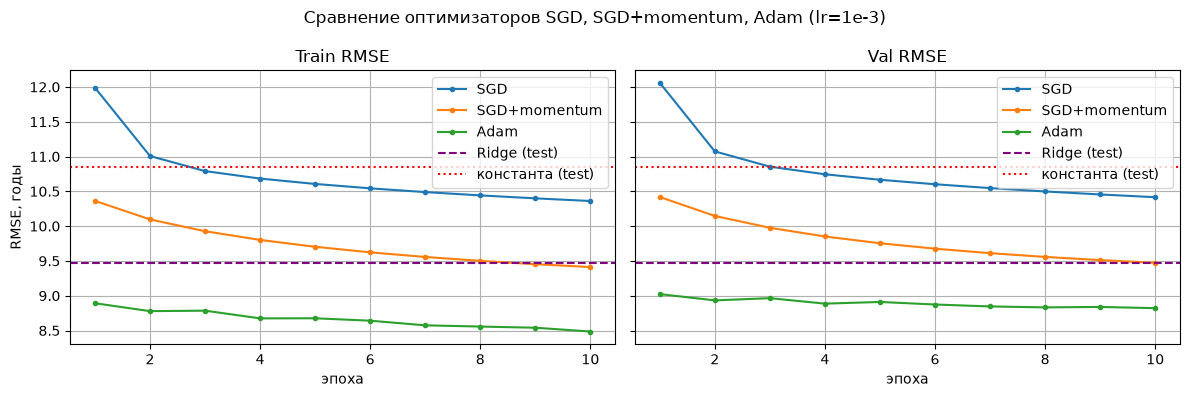

In [113]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
fig.suptitle("Сравнение оптимизаторов SGD, SGD+momentum, Adam (lr=1e-3)")
for name, (_, logs) in results.items():
    ep = range(1, len(logs["val_rmse"]) + 1)
    axes[0].plot(ep, logs["train_rmse"], marker=".", label=name)
    axes[1].plot(ep, logs["val_rmse"], marker=".", label=name)
for ax, title in zip(axes, ["Train RMSE", "Val RMSE"]):
    ax.axhline(rmse_for_model, color="purple", ls="--", label="Ridge (test)")
    ax.axhline(best_rmse_metric, color="red", ls=":", label="константа (test)")
    ax.set_title(title)
    ax.set_xlabel("эпоха")
    ax.grid(True)
    ax.legend()
axes[0].set_ylabel("RMSE, годы")
plt.tight_layout()
plt.show()

Все три оптимизатора запущены с 10 эпохами и `lr = 1e-3`.

SGD самый медленный: val RMSE с 12.06 до 10.42, Ridge не достигнут. SGD+momentum=0,9 уже после первой эпохи получает те же 10.42, что SGD после десяти, и к десятой эпохе доходит до 9.47. Adam быстрее обоих: val 9.02 после первой эпохи и 8.82 после десятой, это лучше Ridge. Разрыв train-val у Adam вырастает с 0.13 до 0.34. После седьмой эпохи val улучшается мало, с 8.85 до 8.82, и слегка колеблется, но минимум всё ещё на последней эпохе.

**Дальше использую Adam с `lr = 1e-3`.**

**Задание 10 (1 балл).** Теперь сделаем нашу нейронную сеть более сложной. Попробуйте сделать сеть:

- более широкой (то есть увеличить размерность скрытого слоя, например, вдвое)
- более глубокой (то есть добавить еще один скрытый слой)

In [114]:
def make_wide_model():
    return nn.Sequential(
        nn.Linear(X_train_std.shape[1], 256),
        nn.ReLU(),
        nn.Linear(256, 1),
        nn.Sigmoid()
    )

def make_deep_model():
    return nn.Sequential(
        nn.Linear(X_train_std.shape[1], 128),
        nn.ReLU(),
        nn.Linear(128, 128),
        nn.ReLU(),
        nn.Linear(128, 1),
        nn.Sigmoid()
    )

In [115]:
adam = lambda p: torch.optim.Adam(p, lr=1e-3)
adam_results = {
    "base": train_and_evaluate(make_model, adam, nn.MSELoss(), "base", 15),
    "wide": train_and_evaluate(make_wide_model, adam, nn.MSELoss(), "wide", 15),
    "deep": train_and_evaluate(make_deep_model, adam, nn.MSELoss(), "deep", 15),
}


base
epoch 01: RMSE train 8.8920 | RMSE val 9.0230
epoch 02: RMSE train 8.7784 | RMSE val 8.9329
epoch 03: RMSE train 8.7852 | RMSE val 8.9646
epoch 04: RMSE train 8.6746 | RMSE val 8.8862
epoch 05: RMSE train 8.6758 | RMSE val 8.9102
epoch 06: RMSE train 8.6411 | RMSE val 8.8737
epoch 07: RMSE train 8.5744 | RMSE val 8.8459
epoch 08: RMSE train 8.5570 | RMSE val 8.8324
epoch 09: RMSE train 8.5398 | RMSE val 8.8388
epoch 10: RMSE train 8.4857 | RMSE val 8.8212
epoch 11: RMSE train 8.4404 | RMSE val 8.8133
epoch 12: RMSE train 8.5006 | RMSE val 8.8484
epoch 13: RMSE train 8.5548 | RMSE val 8.9246
epoch 14: RMSE train 8.4133 | RMSE val 8.8226
epoch 15: RMSE train 8.4303 | RMSE val 8.8350

wide
epoch 01: RMSE train 8.8637 | RMSE val 8.9946
epoch 02: RMSE train 8.7589 | RMSE val 8.9212
epoch 03: RMSE train 8.7725 | RMSE val 8.9642
epoch 04: RMSE train 8.6510 | RMSE val 8.8769
epoch 05: RMSE train 8.6334 | RMSE val 8.9050
epoch 06: RMSE train 8.5602 | RMSE val 8.8422
epoch 07: RMSE train 8

In [116]:
def count_params(model):
    return sum(p.numel() for p in model.parameters())

def results_table(results):
    rows = []
    for name, (model, logs) in results.items():
        best = int(np.argmin(logs["val_rmse"]))
        rows.append({
            "model": name,
            "params": count_params(model),
            "train RMSE": logs["train_rmse"][-1],
            "val RMSE": logs["val_rmse"][-1],
            "best val RMSE": logs["val_rmse"][best],
            "best epoch": best + 1,
            "gap (val - train)": logs["val_rmse"][-1] - logs["train_rmse"][-1],
            "test RMSE": logs["test_rmse"],
        })
    return pd.DataFrame(rows).set_index("model").round(4)

In [117]:
results_table(adam_results)

,params,train RMSE,val RMSE,best val RMSE,best epoch,gap (val - train),test RMSE
model,,,,,,,
base,11777,8.4303,8.8350,8.8133,11,0.4047,8.8578
wide,23553,8.2787,8.8432,8.7976,11,0.5645,8.9283
deep,28289,7.7182,8.7724,8.7161,7,1.0542,8.9467


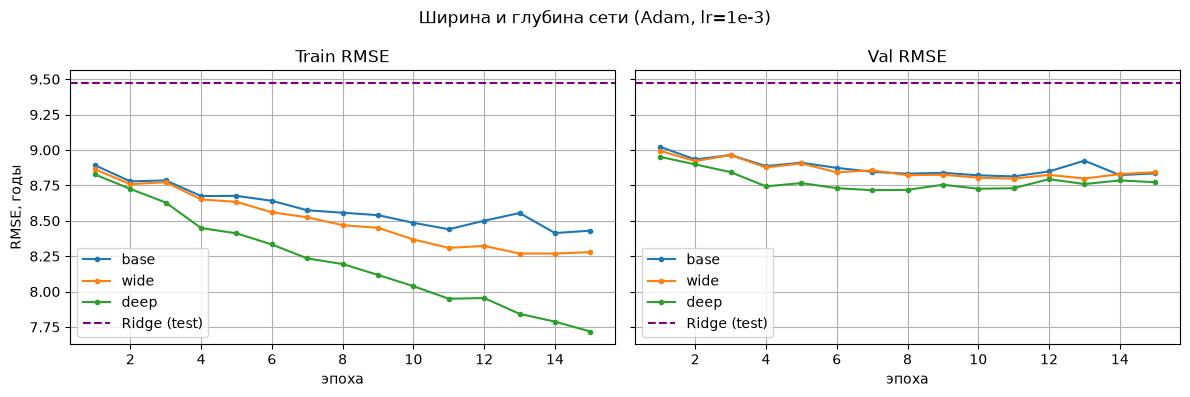

In [118]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
fig.suptitle("Ширина и глубина сети (Adam, lr=1e-3)")
for name, (_, logs) in adam_results.items():
    ep = range(1, len(logs["val_rmse"]) + 1)
    axes[0].plot(ep, logs["train_rmse"], marker=".", label=name)
    axes[1].plot(ep, logs["val_rmse"], marker=".", label=name)
for ax, title in zip(axes, ["Train RMSE", "Val RMSE"]):
    ax.axhline(rmse_for_model, color="purple", ls="--", label="Ridge (test)")
    ax.set_title(title)
    ax.set_xlabel("эпоха")
    ax.grid(True)
    ax.legend()
axes[0].set_ylabel("RMSE, годы")
plt.tight_layout()
plt.show()

Опишите, как увеличение числа параметров модели влияет на качество на обучающей и валидационной выборках (без их описания за работу ставится ноль баллов)

__Ваше подробное описание:__

- Base, скрытый слой 128, 11777 параметров: train 8.43, val 8.84 (лучший 8.81 на 11-ой эпохе), разрыв 0.40, test 8.86. 
- Wide, скрытый слой 256, 23553 параметра: train 8.28, val 8.84 (лучший 8.80 на 11-ой), разрыв 0.56, test 8.93. 
- Deep, два слоя по 128, 28289 параметров: train 7.72, val 8.77 (лучший 8.72 на 7-ой), разрыв 1.05, test 8.95.

Рост числа параметров улучшает подгонку train: 8.43, затем 8.28, затем 7.72. На валидации выигрыш меньше. Удвоение ширины сдвигает лучший val всего примерно на 0.02, а разрыв train-val растёт с 0.40 до 0.56. Второй скрытый слой даёт больший выигрыш на val, 8.72 против 8.81 у base, потому что ещё одна ReLU добавляет новую нелинейную комбинацию признаков. Этот минимум у deep достигается на 7-ой эпохе. Дальше train продолжает падать до 7.72, а val поднимается до 8.77, разрыв становится 1.05 года. Значит, дополнительные параметры запоминают обучающую выборку.

Test RMSE посчитан по весам последней эпохи: 8.86, 8.93 и 8.95.
Далее берем deep.

**Задание 11 (1 балл).** Как вы должны были заметить, более сложная модель стала сильнее переобучаться. Попробуем разные методы регуляризации, чтобы бороться с переобучением. Проведите два эксперимента:

- Добавьте слой дропаута с параметром $p=0.2$ после каждого линейного слоя, кроме последнего.
- Попробуйте batch-нормализацию вместо дропаута. Строго говоря, batch-нормализация не является методом регуляризации, но никто не запрещает нам экспериментировать с ней.

In [119]:
def make_mlp(hidden_sizes, dropout=0.0, batchnorm=False):
    layers = []
    in_features = X_train_std.shape[1]
    for h in hidden_sizes:
        layers.append(nn.Linear(in_features, h))
        if batchnorm:
            layers.append(nn.BatchNorm1d(h))
        layers.append(nn.ReLU())
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        in_features = h
    layers += [nn.Linear(in_features, 1), nn.Sigmoid()]
    return nn.Sequential(*layers)

In [120]:
regularization_results = {
    "deep": train_and_evaluate(make_deep_model, adam, nn.MSELoss(), "deep", epochs=25),
    "deep+dropout(0.2)": train_and_evaluate(lambda: make_mlp([128, 128], dropout=0.2), 
                            adam, nn.MSELoss(), "deep + dropout(0.2)", epochs=25),
    "deep+batchnorm": train_and_evaluate(lambda: make_mlp([128, 128], batchnorm=True),
                            adam, nn.MSELoss(), "deep + batchnorm", epochs=25)
}


deep


epoch 01: RMSE train 8.8269 | RMSE val 8.9520
epoch 02: RMSE train 8.7251 | RMSE val 8.8983
epoch 03: RMSE train 8.6291 | RMSE val 8.8438
epoch 04: RMSE train 8.4486 | RMSE val 8.7430
epoch 05: RMSE train 8.4115 | RMSE val 8.7663
epoch 06: RMSE train 8.3327 | RMSE val 8.7304
epoch 07: RMSE train 8.2344 | RMSE val 8.7161
epoch 08: RMSE train 8.1945 | RMSE val 8.7186
epoch 09: RMSE train 8.1177 | RMSE val 8.7546
epoch 10: RMSE train 8.0383 | RMSE val 8.7261
epoch 11: RMSE train 7.9498 | RMSE val 8.7303
epoch 12: RMSE train 7.9544 | RMSE val 8.7941
epoch 13: RMSE train 7.8428 | RMSE val 8.7596
epoch 14: RMSE train 7.7878 | RMSE val 8.7849
epoch 15: RMSE train 7.7182 | RMSE val 8.7724
epoch 16: RMSE train 7.7445 | RMSE val 8.8147
epoch 17: RMSE train 7.6651 | RMSE val 8.8676
epoch 18: RMSE train 7.6193 | RMSE val 8.8856
epoch 19: RMSE train 7.6061 | RMSE val 8.8726
epoch 20: RMSE train 7.5662 | RMSE val 8.8312
epoch 21: RMSE train 7.5195 | RMSE val 8.8898
epoch 22: RMSE train 7.5033 | RMSE

In [121]:
results_table(regularization_results)

,params,train RMSE,val RMSE,best val RMSE,best epoch,gap (val - train),test RMSE
model,,,,,,,
deep,28289,7.4320,8.9795,8.7161,7,1.5475,9.1435
deep+dropout(0.2),28289,8.1853,8.7001,8.6625,22,0.5148,8.7396
deep+batchnorm,28801,7.7582,8.7082,8.6682,15,0.9500,8.8481


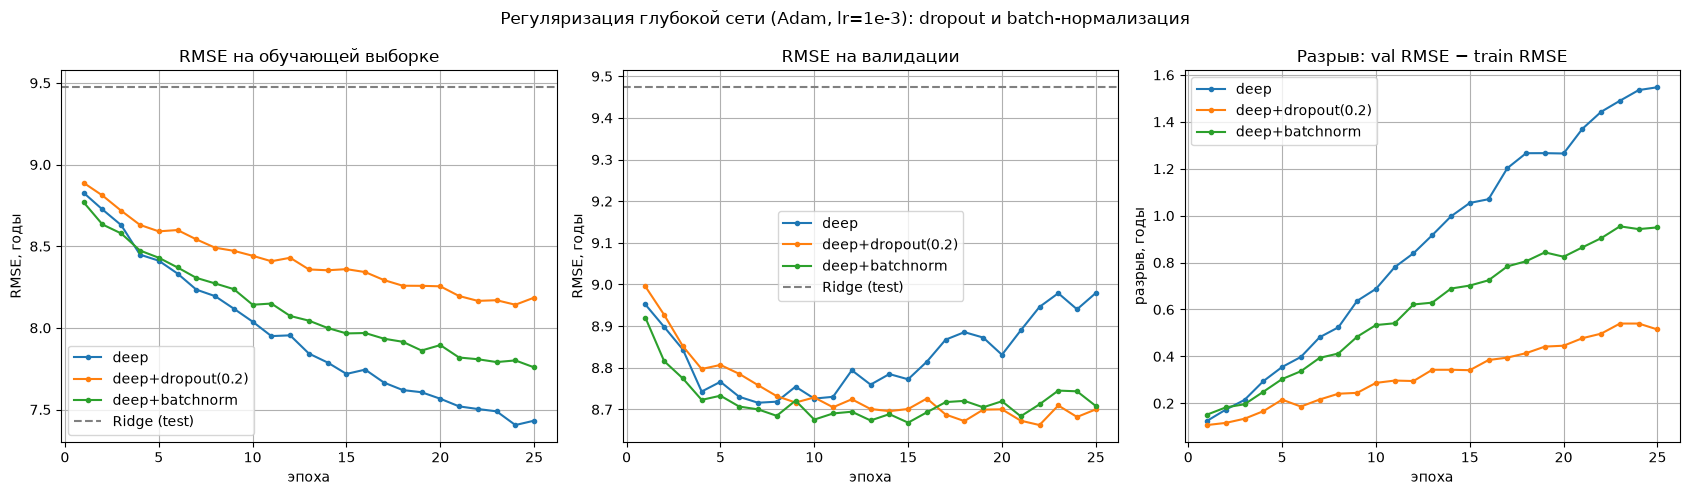

In [122]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for name, (_, logs) in regularization_results.items():
    ep = range(1, len(logs["val_rmse"]) + 1)
    gap = np.array(logs["val_rmse"]) - np.array(logs["train_rmse"])
    axes[0].plot(ep, logs["train_rmse"], marker=".", label=name)
    axes[1].plot(ep, logs["val_rmse"], marker=".", label=name)
    axes[2].plot(ep, gap, marker=".", label=name)

titles = ["RMSE на обучающей выборке", "RMSE на валидации", "Разрыв: val RMSE − train RMSE"]
ylabels = ["RMSE, годы", "RMSE, годы", "разрыв, годы"]
for ax, title, ylabel in zip(axes, titles, ylabels):
    ax.set_title(title)
    ax.set_xlabel("эпоха")
    ax.set_ylabel(ylabel)
    ax.grid(True)
for ax in axes[:2]:
    ax.axhline(rmse_for_model, color="gray", ls="--", label="Ridge (test)")
for ax in axes:
    ax.legend()
fig.suptitle("Регуляризация глубокой сети (Adam, lr=1e-3): dropout и batch-нормализация")
plt.tight_layout()
plt.show()

Опишите результаты экспериментов (без их описания за работу ставится ноль баллов)

__Ваше подробное описание:__

Три варианта глубокой сети, Adam, lr = 1e-3, 25 эпох. Train и val считаются в eval, поэтому Dropout на замере выключен.

Без регуляризации сеть сильнее всего подгоняет train. К 25-ой эпохе train RMSE 7.43, а val после лучшего значения 8.72 на 7-ой эпохе вырастает до 8.98. Разрыв 1.55 года. Test 9.14 близок к Ridge (9.47).

Dropout с p = 0.2 стоит после ReLU каждого скрытого слоя и параметров не добавляет, их по-прежнему 28 289. Train к концу 8.19. Лучший val 8.66 на 22-ой эпохе, финальный val 8.70, разрыв 0.51. После лучшей эпохи val колеблется примерно на 0.04 и вверх не уходит. Test 8.74.

BatchNorm стоит между Linear и ReLU и добавляет 512 параметров, всего 28 801. Лучший val 8.67 на 15-ой эпохе, почти как у Dropout. Train при этом падает до 7.76, разрыв к концу 0.95. Test 8.85.

Дальше беру deep+Dropout: конечный разрыв train-val самый маленький, и val после лучшей эпохи не растёт. Test это подтверждает, в выборе он не участвовал.

**Задание 12 (1 балл).** Теперь, когда мы определились с выбором архитектуры нейронной сети, пора заняться рутиной DL-инженера &mdash; перебором гиперпараметров. Подберите оптимальное значение lr по значению RMSE на валидации (по логарифмической сетке, достаточно посмотреть 3-4 значения). Затем подберите оптимальное значение weight decay для данного lr (тоже по логарифмической сетке, типичные значения этого параметра лежат в диапазоне $[10^{-6}, 10^{-3}]$, но не забудьте включить нулевое значение в сетку). Постройте графики зависимости RMSE на трейне и на валидации от значений параметров. Прокомментируйте получившиеся зависимости.

In [123]:
def make_selected_model():
    return make_mlp([128, 128], dropout=0.2)

def summarize(logs):
    best_epoch = int(np.argmin(logs["val_rmse"]))
    return {
        "train RMSE": logs["train_rmse"][-1],
        "val RMSE": logs["val_rmse"][-1],
        "best val RMSE": logs["val_rmse"][best_epoch],
        "best epoch": best_epoch + 1,
        "train RMSE best": logs["train_rmse"][best_epoch],
        "test RMSE": logs["test_rmse"],
    }

In [124]:
lr_grid = [1e-4, 3e-4, 1e-3, 3e-3]
lr_results = {}
for lr in lr_grid:
    make_opt = lambda p, lr=lr: torch.optim.Adam(p, lr=lr)
    lr_results[lr] = train_and_evaluate(make_selected_model, make_opt, nn.MSELoss(), f"lr={lr:g}", epochs=25)


lr=0.0001
epoch 01: RMSE train 9.2311 | RMSE val 9.3098
epoch 02: RMSE train 9.0050 | RMSE val 9.0995
epoch 03: RMSE train 8.9025 | RMSE val 9.0073
epoch 04: RMSE train 8.8421 | RMSE val 8.9528
epoch 05: RMSE train 8.7655 | RMSE val 8.8953
epoch 06: RMSE train 8.7682 | RMSE val 8.9033
epoch 07: RMSE train 8.7045 | RMSE val 8.8552
epoch 08: RMSE train 8.6740 | RMSE val 8.8339
epoch 09: RMSE train 8.6482 | RMSE val 8.8204
epoch 10: RMSE train 8.6139 | RMSE val 8.8014
epoch 11: RMSE train 8.6142 | RMSE val 8.8107
epoch 12: RMSE train 8.5661 | RMSE val 8.7772
epoch 13: RMSE train 8.5420 | RMSE val 8.7635
epoch 14: RMSE train 8.5343 | RMSE val 8.7647
epoch 15: RMSE train 8.5179 | RMSE val 8.7571
epoch 16: RMSE train 8.4831 | RMSE val 8.7399
epoch 17: RMSE train 8.4700 | RMSE val 8.7420
epoch 18: RMSE train 8.4467 | RMSE val 8.7223
epoch 19: RMSE train 8.4187 | RMSE val 8.7149
epoch 20: RMSE train 8.4182 | RMSE val 8.7206
epoch 21: RMSE train 8.4117 | RMSE val 8.7183
epoch 22: RMSE train 8.

In [125]:
lr_table = pd.DataFrame({lr: summarize(logs) for lr, (_, logs) in lr_results.items()}).T
lr_table.index.name = "lr"
best_lr = lr_table["best val RMSE"].idxmin()
print(f"Лучший lr по val RMSE: {best_lr:g}")
lr_table.round(4)

Лучший lr по val RMSE: 0.0003


,train RMSE,val RMSE,best val RMSE,best epoch,train RMSE best,test RMSE
lr,,,,,,
0.0001,8.3417,8.6954,8.6899,23.0,8.3433,8.7054
0.0003,8.1534,8.6610,8.6404,23.0,8.1444,8.7050
0.0010,8.1853,8.7001,8.6625,22.0,8.1655,8.7396
0.0030,8.3606,8.7599,8.7543,17.0,8.4383,8.7307


In [126]:
wd_grid = [0, 1e-6, 1e-5, 1e-4, 1e-3]
wd_results = {}
for wd in wd_grid:
    make_opt = lambda p, wd=wd: torch.optim.Adam(p, lr=best_lr, weight_decay=wd)
    wd_results[wd] = train_and_evaluate(make_selected_model, make_opt, nn.MSELoss(),
                                        f"lr={best_lr:g}, wd={wd:g}", epochs=25)

wd_table = pd.DataFrame({wd: summarize(logs) for wd, (_, logs) in wd_results.items()}).T
wd_table.index.name = "weight_decay"
best_wd = wd_table["best val RMSE"].idxmin()
print(f"Лучший weight_decay при lr={best_lr:g}: {best_wd:g}")
wd_table.round(4)


lr=0.0003, wd=0
epoch 01: RMSE train 8.9788 | RMSE val 9.0788
epoch 02: RMSE train 8.8119 | RMSE val 8.9300
epoch 03: RMSE train 8.7205 | RMSE val 8.8570
epoch 04: RMSE train 8.6537 | RMSE val 8.8176
epoch 05: RMSE train 8.5984 | RMSE val 8.7950
epoch 06: RMSE train 8.6141 | RMSE val 8.8108
epoch 07: RMSE train 8.5450 | RMSE val 8.7693
epoch 08: RMSE train 8.4918 | RMSE val 8.7450
epoch 09: RMSE train 8.4651 | RMSE val 8.7377
epoch 10: RMSE train 8.4333 | RMSE val 8.7249
epoch 11: RMSE train 8.3974 | RMSE val 8.7083
epoch 12: RMSE train 8.3942 | RMSE val 8.7128
epoch 13: RMSE train 8.3322 | RMSE val 8.6861
epoch 14: RMSE train 8.3418 | RMSE val 8.7046
epoch 15: RMSE train 8.3237 | RMSE val 8.6992
epoch 16: RMSE train 8.2858 | RMSE val 8.6798
epoch 17: RMSE train 8.2697 | RMSE val 8.6940
epoch 18: RMSE train 8.2327 | RMSE val 8.6685
epoch 19: RMSE train 8.2184 | RMSE val 8.6707
epoch 20: RMSE train 8.2370 | RMSE val 8.6816
epoch 21: RMSE train 8.2074 | RMSE val 8.6914
epoch 22: RMSE tr

,train RMSE,val RMSE,best val RMSE,best epoch,train RMSE best,test RMSE
weight_decay,,,,,,
0.000000,8.1534,8.6610,8.6404,23.0,8.1444,8.7050
0.000001,8.1638,8.6784,8.6493,22.0,8.1562,8.7074
0.000010,8.3288,8.6803,8.6669,22.0,8.3283,8.6750
0.000100,8.7925,8.9059,8.8674,22.0,8.7452,8.8124
0.001000,9.1345,9.1910,9.1619,21.0,9.1033,9.0581


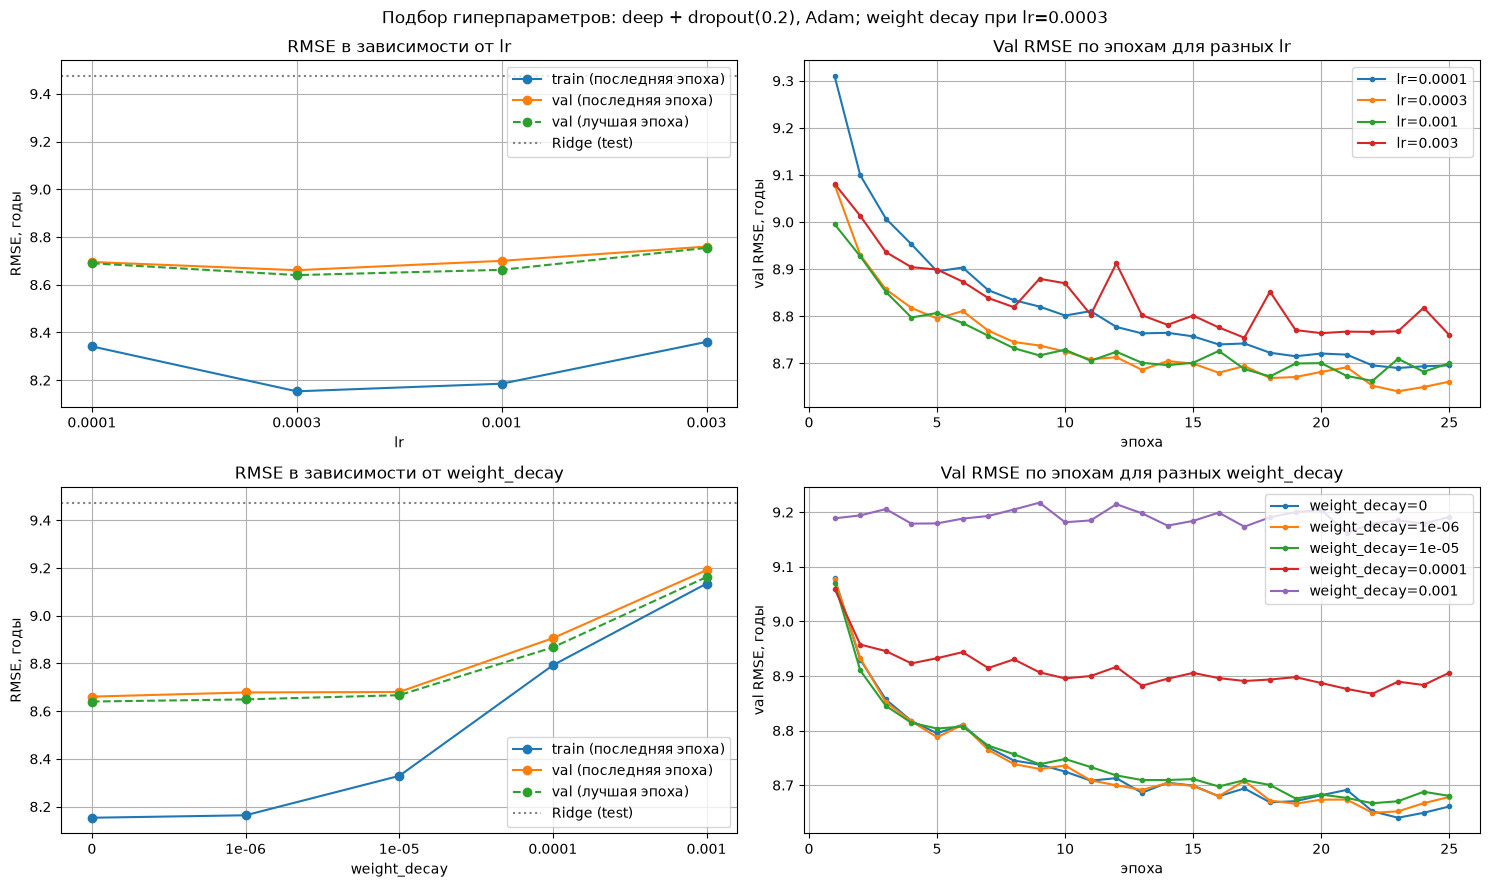

In [127]:
def plot_param_search(table, results, param_name, axes):
    labels = [f"{v:g}" for v in table.index]
    x = np.arange(len(labels))

    ax = axes[0]
    ax.plot(x, table["train RMSE"], marker="o", label="train (последняя эпоха)")
    ax.plot(x, table["val RMSE"], marker="o", label="val (последняя эпоха)")
    ax.plot(x, table["best val RMSE"], marker="o", ls="--", label="val (лучшая эпоха)")
    ax.axhline(rmse_for_model, color="gray", ls=":", label="Ridge (test)")
    ax.set_xticks(x, labels)
    ax.set_xlabel(param_name)
    ax.set_ylabel("RMSE, годы")
    ax.set_title(f"RMSE в зависимости от {param_name}")
    ax.grid(True)
    ax.legend()

    ax = axes[1]
    for v, (_, logs) in results.items():
        ep = range(1, len(logs["val_rmse"]) + 1)
        ax.plot(ep, logs["val_rmse"], marker=".", label=f"{param_name}={v:g}")
    ax.set_xlabel("эпоха")
    ax.set_ylabel("val RMSE, годы")
    ax.set_title(f"Val RMSE по эпохам для разных {param_name}")
    ax.grid(True)
    ax.legend()

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
plot_param_search(lr_table, lr_results, "lr", axes[0])
plot_param_search(wd_table, wd_results, "weight_decay", axes[1])
fig.suptitle(f"Подбор гиперпараметров: deep + dropout(0.2), Adam; weight decay при lr={best_lr:g}")
plt.tight_layout()
plt.show()

Опишите результаты экспериментов (без их описания за работу ставится ноль баллов)

__Ваше подробное описание:__

Сетка `lr`: 1e-4, 3e-4, 1e-3, 3e-3. Одна и та же сеть deep+Dropout(0.2), Adam, 25 эпох. Критерий - лучший val RMSE.

| lr | train, последняя | val, последняя | лучший val | эпоха | test |
|---|---:|---:|---:|---:|---:|
| 1e-4 | 8.34 | 8.70 | 8.69 | 23 | 8.71 |
| 3e-4 | 8.15 | 8.66 | 8.64 | 23 | 8.71 |
| 1e-3 | 8.19 | 8.70 | 8.66 | 22 | 8.74 |
| 3e-3 | 8.36 | 8.76 | 8.75 | 17 | 8.73 |

При 1e-4 шаг мал: к 25-ой эпохе val всё ещё 8.69. При 3e-4 лучший val 8.64 на 23-ой эпохе, и к концу он остаётся 8.66. При 1e-3 лучшая точка близко 8.66, но к последней эпохе val поднимается до 8.70. Разрыв train-val у 3e-4 и 1e-3 около 0.5 года.

Для `lr = 3e-4` сетка weight decay: 0, 1e-6, 1e-5, 1e-4, 1e-3.

| weight decay | train, последняя | val, последняя | лучший val | эпоха | test |
|---|---:|---:|---:|---:|---:|
| 0 | 8.15 | 8.66 | 8.64 | 23 | 8.71 |
| 1e-6 | 8.16 | 8.68 | 8.65 | 22 | 8.71 |
| 1e-5 | 8.33 | 8.68 | 8.67 | 22 | 8.68 |
| 1e-4 | 8.79 | 8.91 | 8.87 | 22 | 8.81 |
| 1e-3 | 9.13 | 9.19 | 9.16 | 21 | 9.06 |

С ростом weight decay train RMSE растёт, с 8.15 до 9.13. Val тоже лучший при нуле и портится. При 1e-3 разрыв train-val доходит до 0.06, потому что сеть недообучается. Dropout уже держит переобучение, дополнительный L2-штраф только уменьшает полезные веса. Прогон с weight decay 0 совпал с отдельным прогоном `lr = 3e-4`.

Дальше беру Adam, `lr = 3e-4`, weight decay 0. У weight decay 1e-5 test RMSE чуть лучше, 8.68 против 8.71, но val хуже, поэтому этот вариант не беру. Test в обеих сетках посчитан по весам последней эпохи.

> Как вы могли заметить, еще одна рутина DL-инженера &mdash; утомительное ожидание обучения моделей.

> заметил`))`



**Задание 13 (6 баллов).**

Думаю направление размышлений вы поняли. Постарайтесь с помощью своих экспериментов выбить максимально возможное значение RMSE на тестовой выборке. Соотношение между полученным значением метрики на тестовой выборке и баллами за задание следующее:

- $\text{RMSE} \le 8.90 $ &mdash; 2 балла
- $\text{RMSE} \le 8.80 $ &mdash; 4 балла
- $\text{RMSE} \le 8.75 $ &mdash; 6 баллов

**Различные трюки, которые можно попробовать:**

1. Попробуйте делать во время обучения раннюю остановку обучения и сохранять модель в тот момент, когда качество на валидации начало ухудшаься, то есть модель начала переобучаться
2. Попробуйте усложнить архитектуру нейросет
    - Больше/меньше нейронов
    - Больше/меньше слоёв
    - Другие функции активации (tanh, relu, leaky relu, elu etc)
    - Регуляризация (dropout, l1,l2)
3. Попробуйте другие оптимизаторы, а также смену скорости обучения по расписанию.

И это далеко не полный список. Обратите внимание, что делать grid_search для больших сеток это довольно времязатратное занятие... Попробовать несколько значений, как мы делали в заданиях выше, адекватно, но делать какой-то огромный перебор будет самоубийством.

Логгируйте свои эксперименты. За один прогон пробуйте одно изменение. Иначе будет непонятно какие именно изменения улучшили качество, а какие ухудшили. 

In [128]:
# copy нужен для copy.deepcopy, без этого сохранённые веса не останутся снимком
import copy

In [129]:
def train_13(make_optimizer, name, epochs=25, use_scheduler=False):
    set_global_seed(42)

    model = make_selected_model().to(device)
    optimizer = make_optimizer(model.parameters())
    mse = nn.MSELoss()

    scheduler = (torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)
                 if use_scheduler else None)
    train_loader = DataLoader(train_loader_std.dataset, batch_size=64, shuffle=True, 
                            generator=torch.Generator().manual_seed(42))

    logs = {"train_rmse": [], "val_rmse": [], "lr": []}
    best_val, best_state = float("inf"), None
    print(f"\n{name}")
    for epoch in range(1, epochs + 1):
        logs["lr"].append(optimizer.param_groups[0]["lr"])
        training_epoch(model, optimizer, mse, train_loader)

        train_rmse = rmse_in_years(model, mse, train_eval_loader_std)
        val_rmse = rmse_in_years(model, mse, val_loader_std)

        logs["train_rmse"].append(train_rmse)
        logs["val_rmse"].append(val_rmse)

        if val_rmse < best_val:
            best_val, best_state = val_rmse, copy.deepcopy(model.state_dict())
        if scheduler is not None:
            scheduler.step(val_rmse)
            
        print(f"epoch {epoch:02d}: lr {logs['lr'][-1]:.1e} | RMSE train {train_rmse:.4f} | RMSE val {val_rmse:.4f}")

    last_state = copy.deepcopy(model.state_dict())
    return model, logs, last_state, best_state

После подбора lr и weight_decay оставляем ту же сеть и те же 25 эпох. Сначала берём веса последней эпохи, затем веса эпохи с лучшим val. Затем к этому добавляем ReduceLROnPlateau(factor=0.5, patience=2): если val не улучшается две эпохи подряд, шаг уменьшается вдвое. Так проверим, мешает ли постоянный lr дойти до минимума, когда качество уже вышло на плато.

In [130]:
make_opt = lambda p: torch.optim.Adam(p, lr=best_lr, weight_decay=best_wd)

model_plain, logs_plain, last_plain, best_plain = train_13(make_opt, "Adam, последняя эпоха", use_scheduler=False)
model_sched, logs_sched, last_sched, best_sched = train_13(make_opt, "Adam + ReduceLROnPlateau", use_scheduler=True)

print("Совпадение с заданием 12:", np.abs(np.array(logs_plain["val_rmse"]) - np.array(wd_results[best_wd][1]["val_rmse"])).max())


Adam, последняя эпоха
epoch 01: lr 3.0e-04 | RMSE train 8.9788 | RMSE val 9.0788
epoch 02: lr 3.0e-04 | RMSE train 8.8119 | RMSE val 8.9300
epoch 03: lr 3.0e-04 | RMSE train 8.7205 | RMSE val 8.8570
epoch 04: lr 3.0e-04 | RMSE train 8.6537 | RMSE val 8.8176
epoch 05: lr 3.0e-04 | RMSE train 8.5984 | RMSE val 8.7950
epoch 06: lr 3.0e-04 | RMSE train 8.6141 | RMSE val 8.8108
epoch 07: lr 3.0e-04 | RMSE train 8.5450 | RMSE val 8.7693
epoch 08: lr 3.0e-04 | RMSE train 8.4918 | RMSE val 8.7450
epoch 09: lr 3.0e-04 | RMSE train 8.4651 | RMSE val 8.7377
epoch 10: lr 3.0e-04 | RMSE train 8.4333 | RMSE val 8.7249
epoch 11: lr 3.0e-04 | RMSE train 8.3974 | RMSE val 8.7083
epoch 12: lr 3.0e-04 | RMSE train 8.3942 | RMSE val 8.7128
epoch 13: lr 3.0e-04 | RMSE train 8.3322 | RMSE val 8.6861
epoch 14: lr 3.0e-04 | RMSE train 8.3418 | RMSE val 8.7046
epoch 15: lr 3.0e-04 | RMSE train 8.3237 | RMSE val 8.6992
epoch 16: lr 3.0e-04 | RMSE train 8.2858 | RMSE val 8.6798
epoch 17: lr 3.0e-04 | RMSE train

In [135]:
def val_of(model, state):
    model.load_state_dict(state)
    return rmse_in_years(model, nn.MSELoss(), val_loader_std)

candidates = {
    "1) последняя эпоха": (model_plain, last_plain),
    "2) лучшая эпоха по val": (model_plain, best_plain),
    "3) ReduceLROnPlateau": (model_sched, best_sched),
}
task13_table = pd.DataFrame({name: {"val RMSE": val_of(m, s)} for name, (m, s) in candidates.items()}).T
task13_table["best epoch"] = [len(logs_plain["val_rmse"]),
                              int(np.argmin(logs_plain["val_rmse"])) + 1,
                              int(np.argmin(logs_sched["val_rmse"])) + 1]
task13_table.round(4)

,val RMSE,best epoch
1) последняя эпоха,8.6610,25
2) лучшая эпоха по val,8.6404,23
3) ReduceLROnPlateau,8.6312,23


In [136]:
for name, (model, state) in candidates.items():
    model.load_state_dict(state)
    test_rmse = rmse_in_years(model, nn.MSELoss(), test_loader_std)
    print(f"{name}: Test RMSE = {test_rmse:.4f}")

1) последняя эпоха: Test RMSE = 8.7050
2) лучшая эпоха по val: Test RMSE = 8.6960
3) ReduceLROnPlateau: Test RMSE = 8.6961


In [137]:
best_name = task13_table["val RMSE"].idxmin()
best_model, best_state = candidates[best_name]
best_model.load_state_dict(best_state)
final_test_rmse = rmse_in_years(best_model, nn.MSELoss(), test_loader_std)
print(f"Выбрана модель: {best_name}")
print(f"Test RMSE: {final_test_rmse:.4f}")

Выбрана модель: 3) ReduceLROnPlateau
Test RMSE: 8.6961


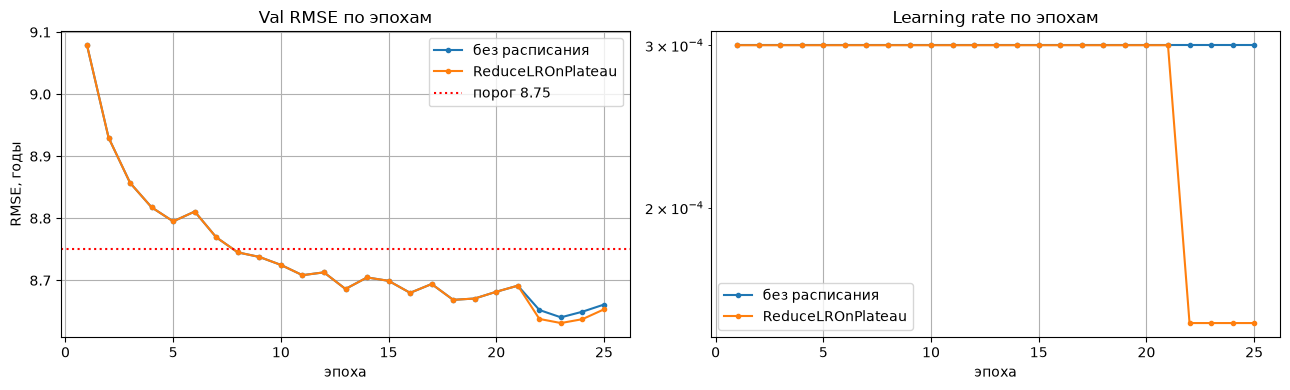

In [138]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, logs in [("без расписания", logs_plain), ("ReduceLROnPlateau", logs_sched)]:
    ep = range(1, len(logs["val_rmse"]) + 1)
    axes[0].plot(ep, logs["val_rmse"], marker=".", label=name)
    axes[1].plot(ep, logs["lr"], marker=".", label=name)
axes[0].axhline(8.75, color="red", ls=":", label="порог 8.75")
axes[0].set_title("Val RMSE по эпохам"); axes[0].set_ylabel("RMSE, годы")
axes[1].set_title("Learning rate по эпохам"); axes[1].set_yscale("log")
for ax in axes:
    ax.set_xlabel("эпоха"); ax.grid(True); ax.legend()
plt.tight_layout(); plt.show()

Опишите результаты экспериментов (без их описания за работу ставится ноль баллов)

__Ваше подробное описание:__

Сеть: deep + Dropout(0.2), Adam, lr = 3e-4, weight decay = 0, 25 эпох. Из трёх вариантов оставляю тот, у которого меньше val RMSE.

Сначала один запуск без расписания learning rate. После обучения сравниваю два набора весов этого запуска:

- Эпоха 25 последняя: Train RMSE 8.153, val RMSE 8.661, разрыв 0.51. Кривая val совпала с лучшим запуском задания 12.
- Эпоха 23: Это эпоха того же запуска, на которой val RMSE был минимальным: 8.640. Обучение заново не запускал, взял веса, которые сеть уже имела на 23-ей эпохе. Поэтому val здесь меньше на 0.021: так и задумано, раз из 25 эпох выбрана лучшая по val.

Второй запуск отличается одним изменением: добавлен `ReduceLROnPlateau(factor=0.5, patience=2)`. Если val несколько эпох не становится лучше, шаг уменьшается вдвое. До 21 эпохи кривая совпадает с первым запуском. На 18 эпохе val был 8.669, на 19–21 он был хуже, и к 22 эпохе lr снизился с 3e-4 до 1.5e-4. После этого val ещё упал: 8.638 на 22 эпохе и 8.631 на 23. В модель беру веса 23 эпохи.

| запуск | какие веса взяты | val RMSE | эпоха | test RMSE |
|---|---|---:|---:|---:|
| 1 | последняя эпоха | 8.661 | 25 | 8.705 |
| 1 | лучшая эпоха по val | 8.640 | 23 | 8.696 |
| 2 | лучшая эпоха по val, с ReduceLROnPlateau | 8.631 | 23 | 8.696 |

По val оставляю второй запуск, веса 23 эпохи. Test RMSE этой модели 8.696. На тесте уменьшение lr ничего не изменило: у лучшей эпохи первого запуска тест тоже 8.696. Обе эти точки лучше последней эпохи 8.705. Дальше ничего не менял.

## Бонус (0.1 балла)

Прикрепите фотографию того, как вы начали этот сентябрь. Какую самую классную эмоцию вы испытали за прошедший месяц?

__место для картики и эмоции__


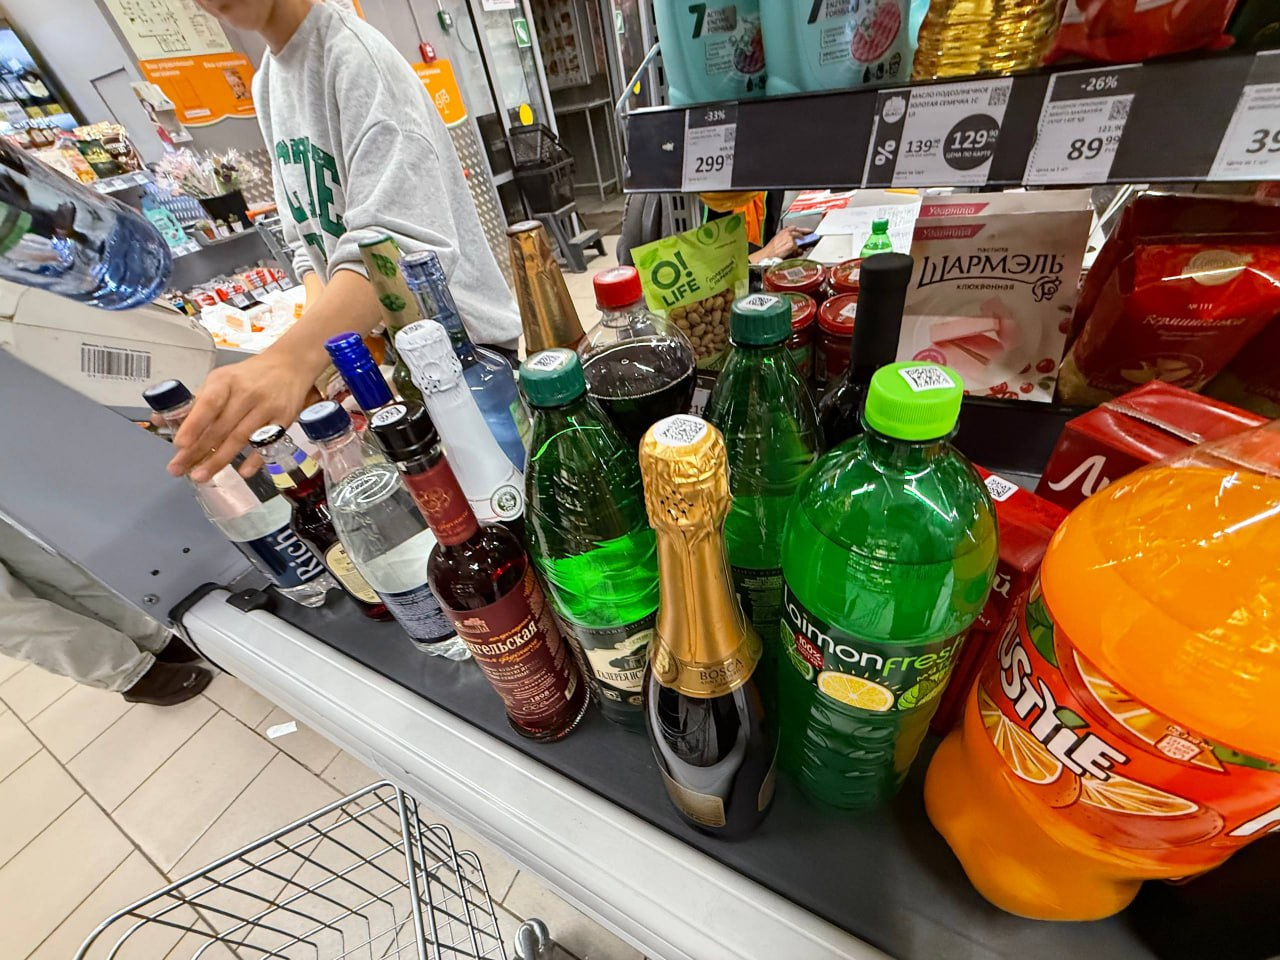

После ничего не помню...